# Database overview
Summarises table sizes, field coverage, top work types and polity coverage of the Cultura database (`cultura_enriched_v3.2`). An individual has a Cliopatria polity when its active life is matched to one (`main_polity`).

In [1]:
import random
import tempfile
import numpy as np
import polars as pl
import duckdb
from style import *
from identifiers import person_identifier_pids

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(60)

apply_style()

## Connect

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
con.execute('SET VARIABLE person_pids = ?::VARCHAR[]', [person_identifier_pids()])

## Load data
### Field coverage

In [3]:
field_coverage_wide = con.sql('''
    SELECT
        COUNT(*)                                                   AS total_individuals,
        COUNT(*) FILTER (WHERE len(list_filter(individual.birth_date, recorded -> recorded.field_provenance['year'].rule IS NULL)) > 0)              AS date_of_birth,
        COUNT(*) FILTER (WHERE len(list_filter(individual.death_date, recorded -> recorded.field_provenance['year'].rule IS NULL)) > 0)              AS date_of_death,
        COUNT(*) FILTER (WHERE len(list_filter(individual.floruit_date, recorded -> recorded.field_provenance['year'].rule IS NULL)) > 0)            AS floruit_date,
        COUNT(individual.place_of_birth.entity.qid)                         AS place_of_birth,
        COUNT(individual.place_of_death.entity.qid)                         AS place_of_death,
        COUNT(*) FILTER (WHERE len(individual.country_of_citizenship) > 0)  AS nationality,
        COUNT(*) FILTER (WHERE len(individual.occupation) > 0)              AS occupation,
        COUNT(individual.sex_or_gender)                                     AS gender,
        COUNT(*) FILTER (WHERE len(individual.writing_language) > 0)        AS writing_language,
        COUNT(*) FILTER (WHERE len(individual.sitelink) > 0)                AS wikimedia_sitelinks,
        COUNT(*) FILTER (WHERE len(list_filter(individual.external_id, identifier_value -> list_contains(getvariable('person_pids'), identifier_value.pid))) > 0) AS external_identifiers,
        COUNT(individual_enriched.start_of_active_life.year)                AS active_life,
        COUNT(individual_enriched.main_polity.polity.cliopatria_id)         AS cliopatria_polity_mapping
    FROM individual
    JOIN individual_enriched
      ON individual_enriched.entity.qid = individual.entity.qid
''').pl()

print('shape:', field_coverage_wide.shape)
field_coverage_wide

shape: (1, 14)


total_individuals,date_of_birth,date_of_death,floruit_date,place_of_birth,place_of_death,nationality,occupation,gender,writing_language,wikimedia_sitelinks,external_identifiers,active_life,cliopatria_polity_mapping
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
13002840,7487873,3531410,68639,3724761,1585470,5569980,9038068,8965380,225824,4959526,8674206,5072222,3624596


## Preprocessing

### Field coverage table

In [4]:
PROPERTY_LABELS = {
    'total_individuals': 'Total individuals',
    'date_of_birth': 'Date of birth',
    'date_of_death': 'Date of death',
    'floruit_date': 'Floruit date',
    'place_of_birth': 'Place of birth',
    'place_of_death': 'Place of death',
    'nationality': 'Nationality',
    'occupation': 'Occupation',
    'gender': 'Gender',
    'writing_language': 'Writing language',
    'wikimedia_sitelinks': 'Wikimedia sitelinks (>=1)',
    'external_identifiers': 'External identifiers (>=1)',
    'active_life': 'Active life, first to last work (computed)',
    'cliopatria_polity_mapping': 'Cliopatria polity of the active life',
}

total_individuals = field_coverage_wide['total_individuals'].item()

def to_long(wide, key, value):
    return (
        wide.transpose(include_header=True, header_name=key, column_names=[value])
        .with_columns((pl.col(value).cast(pl.Float64) / total_individuals * 100).round(1).alias('% of total'))
    )

field_coverage = to_long(field_coverage_wide, 'Property', 'Individuals').with_columns(pl.col('Property').replace(PROPERTY_LABELS))
assert field_coverage['% of total'].max() <= 100
field_coverage.head()

Property,Individuals,% of total
str,i64,f64
"""Total individuals""",13002840,100.0
"""Date of birth""",7487873,57.6
"""Date of death""",3531410,27.2
"""Floruit date""",68639,0.5
"""Place of birth""",3724761,28.6


## Tables

### Data extracted at the beginning of the pipeline

In [5]:
field_coverage

Property,Individuals,% of total
str,i64,f64
"""Total individuals""",13002840,100.0
"""Date of birth""",7487873,57.6
"""Date of death""",3531410,27.2
"""Floruit date""",68639,0.5
"""Place of birth""",3724761,28.6
"""Place of death""",1585470,12.2
"""Nationality""",5569980,42.8
"""Occupation""",9038068,69.5
"""Gender""",8965380,68.9


### Table 1: journal layout

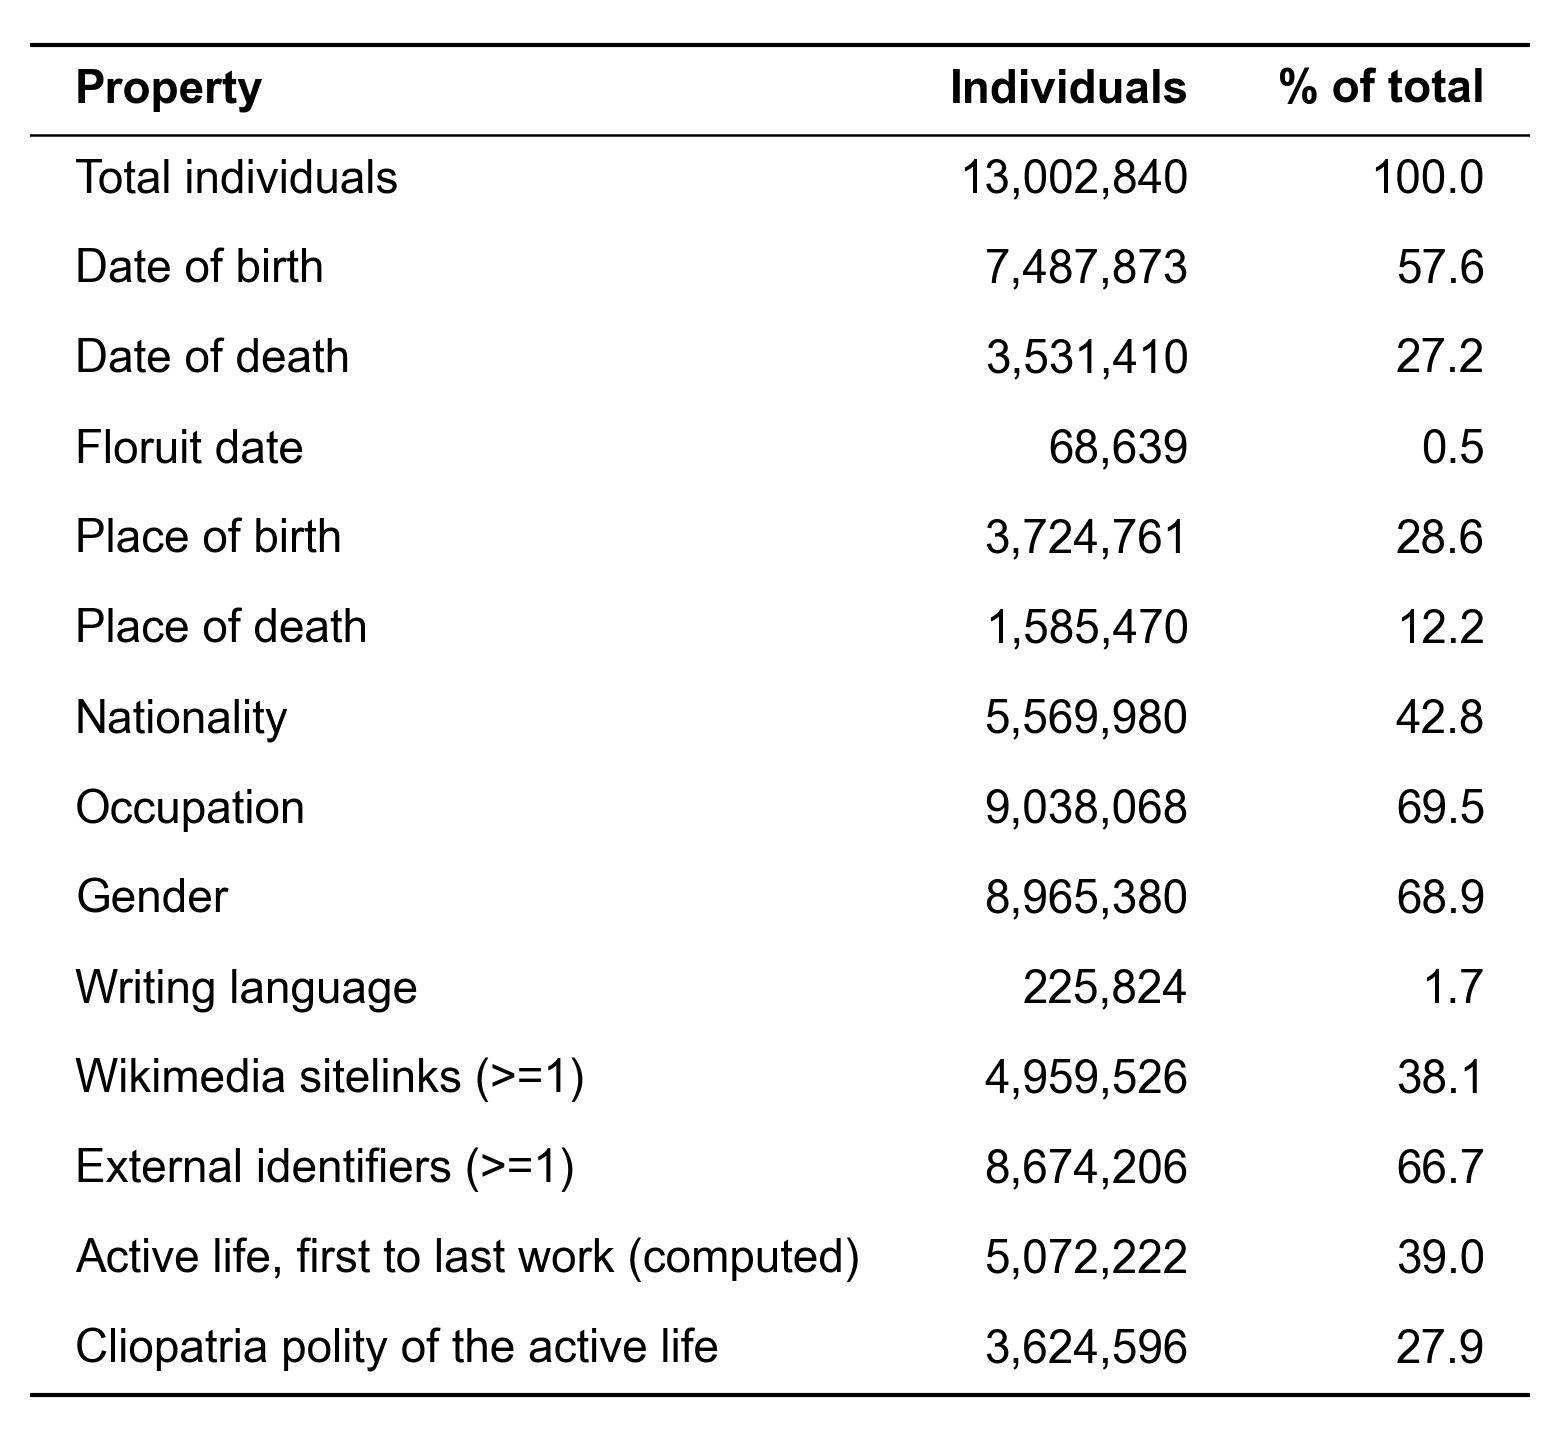

In [6]:
show_table(field_coverage, decimals=1)

### Number of unique values for each property

In [7]:
UNIQUE_VALUE_QUERIES = {
    'Place of birth': 'SELECT COUNT(DISTINCT individual.place_of_birth.entity.qid) FROM individual',
    'Place of death': 'SELECT COUNT(DISTINCT individual.place_of_death.entity.qid) FROM individual',
    'Cities (urban settlements)': 'SELECT COUNT(*) FROM place WHERE place.is_settlement',
    'Country of citizenship': 'SELECT COUNT(DISTINCT citizenship.entity.qid) FROM individual, UNNEST(individual.country_of_citizenship) AS t(citizenship)',
    'Occupation': 'SELECT COUNT(DISTINCT held_occupation.entity.qid) FROM individual, UNNEST(individual.occupation) AS t(held_occupation)',
    'Writing language': 'SELECT COUNT(DISTINCT language) FROM individual, UNNEST(individual.writing_language) AS t(language)',
    'Gender': 'SELECT COUNT(DISTINCT individual.sex_or_gender) FROM individual',
    'Identifier systems': 'SELECT COUNT(DISTINCT identifier.pid) FROM individual, UNNEST(individual.external_id) AS t(identifier)',
    'Wikimedia sitelinks (language editions)': 'SELECT COUNT(DISTINCT edition.site_url) FROM individual, UNNEST(individual.sitelink) AS t(edition)',
    'Work types': 'SELECT COUNT(DISTINCT work_type.qid) FROM work, UNNEST(work.instance_of) AS t(work_type)',
    'Cliopatria polities (active life)': 'SELECT COUNT(DISTINCT polity_id) FROM individual_enriched, UNNEST(list_transform(individual_enriched.active_life_polity, m -> m.polity.cliopatria_id)) AS t(polity_id)',
}

unique_values = pl.DataFrame({
    'Wikidata Property': list(UNIQUE_VALUE_QUERIES),
    'Unique values': [con.sql(query).fetchone()[0] for query in UNIQUE_VALUE_QUERIES.values()],
})
unique_values

Wikidata Property,Unique values
str,i64
"""Place of birth""",275509
"""Place of death""",130604
"""Cities (urban settlements)""",275955
"""Country of citizenship""",3638
"""Occupation""",22037
"""Writing language""",524
"""Gender""",44
"""Identifier systems""",2342
"""Wikimedia sitelinks (language editions)""",607


### Table 2: journal layout

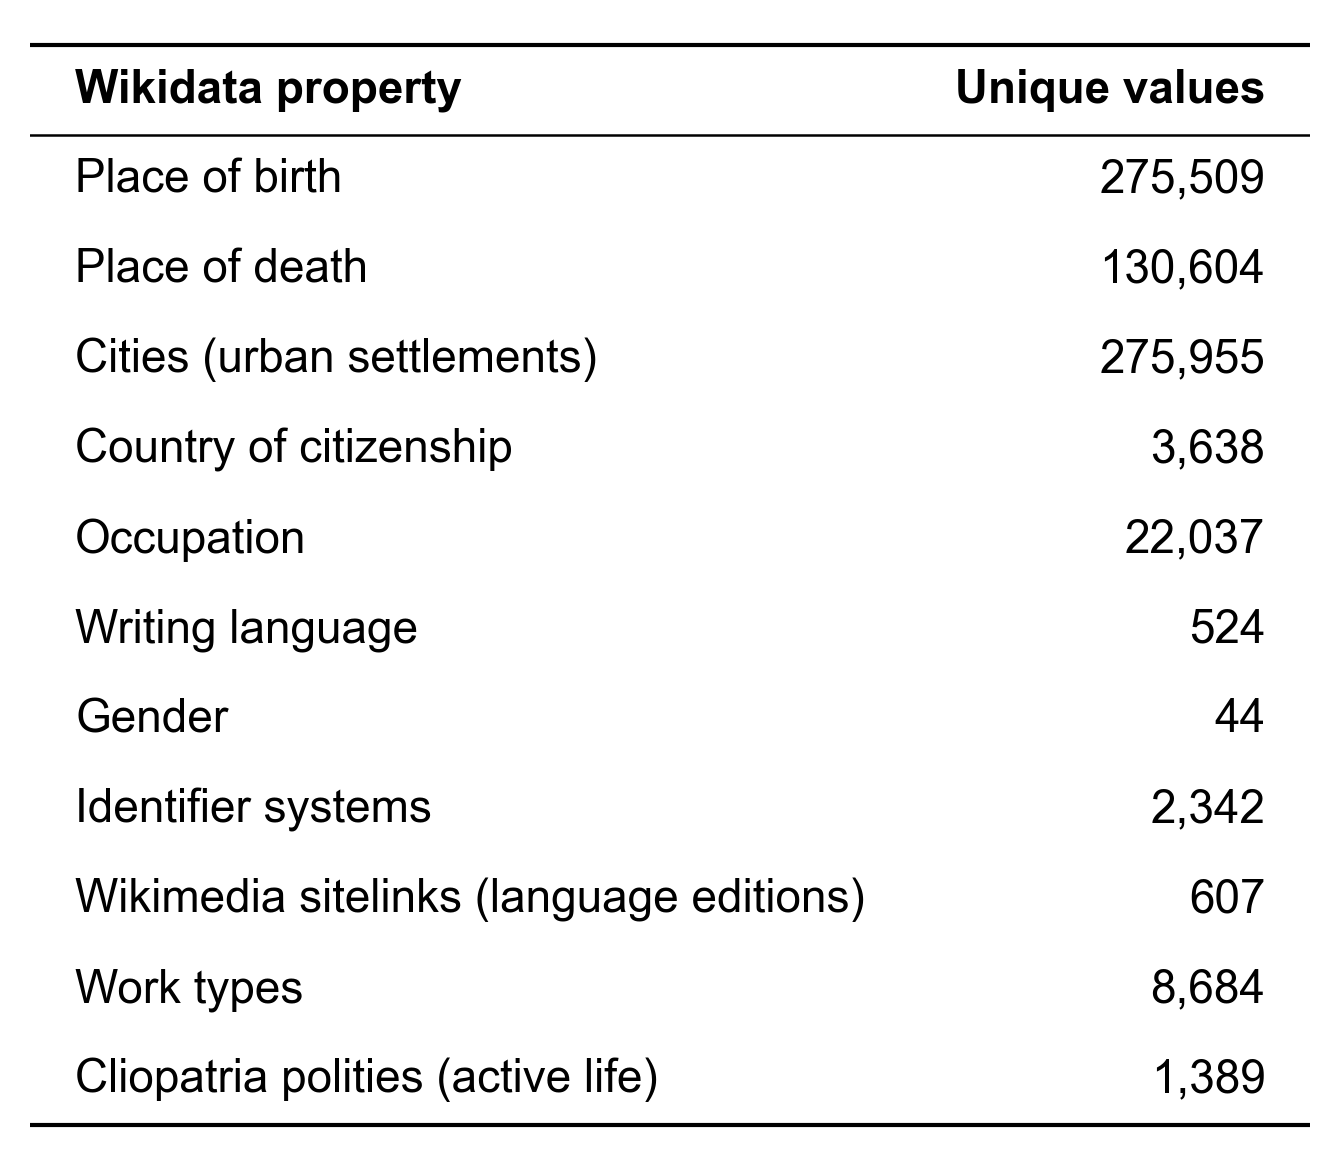

In [8]:
show_table(unique_values.rename({'Wikidata Property': 'Wikidata property'}))